In [1]:
import torch

print("Версия PyTorch:", torch.__version__)

Версия PyTorch: 2.7.0


Количество входов нейрона: 784
Входные данные нейрона: [0.7529411764705882, 0.6431372549019608, 0.3686274509803922, 0.3137254901960784, 0.25882352941176473, 0.2235294117647059, 0.2, 0.1607843137254902, 0.13725490196078433, 0.13725490196078433, 0.3686274509803922, 0.807843137254902, 0.8666666666666667, 0.8117647058823529, 0.3843137254901961, 0.19607843137254902, 0.19215686274509805, 0.19215686274509805, 0.20392156862745098, 0.20392156862745098, 0.2196078431372549, 0.34901960784313724, 0.611764705882353, 0.7647058823529411, 0.788235294117647, 0.792156862745098, 0.8, 0.7725490196078432, 0.7647058823529411, 0.6235294117647059, 0.3764705882352941, 0.3137254901960784, 0.25098039215686274, 0.23529411764705882, 0.21176470588235294, 0.16470588235294117, 0.14901960784313725, 0.17254901960784313, 0.4745098039215686, 0.7176470588235294, 0.788235294117647, 0.8117647058823529, 0.5490196078431373, 0.2, 0.19215686274509805, 0.19215686274509805, 0.21176470588235294, 0.2235294117647059, 0.21960784313725

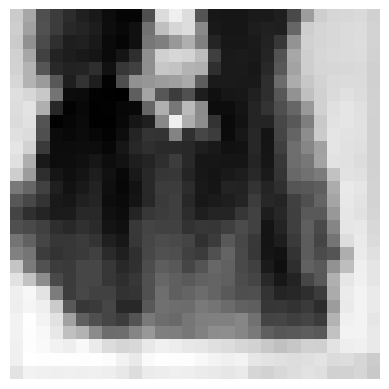

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Загружаем изображение и преобразуем его в чёрно-белое
img = Image.open("data/image-3.png").convert("L")
img = img.resize((28, 28))

# Нормализуем пиксели в диапазон от 0 до 1
pixels = np.array(img) / 255.0

# Преобразуем в одномерный вектор
inputs = pixels.flatten()

print("Количество входов нейрона:", len(inputs))
print("Входные данные нейрона:", inputs.tolist())

# Отобразим изображение
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

In [8]:
img = Image.open("data/image-3.png").convert("L")
img = img.resize((28, 28))
pixels = np.array(img) / 255.0
inputs = pixels.flatten()

np.random.seed(42)

# Создайте переменные weights и bias здесь
weights = np.random.randn(len(inputs))  # Ваш код здесь
bias = np.random.randn()  # Ваш код здесь


print("Количество входов:", len(inputs))
print("Форма weights:", weights.shape)
print("Пример первых 5 весов:", weights[:5])
print("Bias:", bias)

Количество входов: 784
Форма weights: (784,)
Пример первых 5 весов: [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
Bias: 0.5597904479310398


In [9]:
def relu(x):
    return np.maximum(0, x)


def neuron(inputs, weights, bias):
    total = np.dot(inputs, weights) + bias  # взвешенная сумма + смещение
    output = relu(total)
    return output

In [11]:
img = Image.open("data/image-3.png").convert("L").resize((28, 28))
pixels = np.array(img) / 255.0
inputs = pixels.flatten()

np.random.seed(42)
weights = np.random.randn(len(inputs))
bias = np.random.randn()


# Напишите код функции ReLU - верните «обрезанное» значение — минимум 0, максимум x.
# Ваш код здесь
def relu(x):
    return np.maximum(0, x)


# Допишите код функции нейрона.
def neuron(inputs, weights, bias):
    # Вычислите total = сумма + bias
    total = np.dot(inputs, weights) + bias  # Ваш код здесь
    # Примените ReLU
    output = relu(total)  # Ваш код здесь
    return output


output = neuron(inputs, weights, bias)
print("Выход нейрона:", output)

Выход нейрона: 0.0


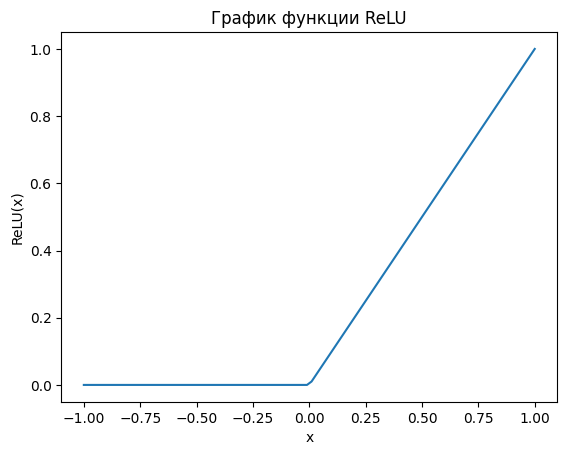

In [12]:
def relu(x):
    return np.maximum(0, x)


x = np.linspace(-1, 1, 100)
y = relu(x)  # применяем вашу функцию

plt.plot(x, y)
plt.title("График функции ReLU")
plt.xlabel("x")
plt.ylabel("ReLU(x)")
plt.show()

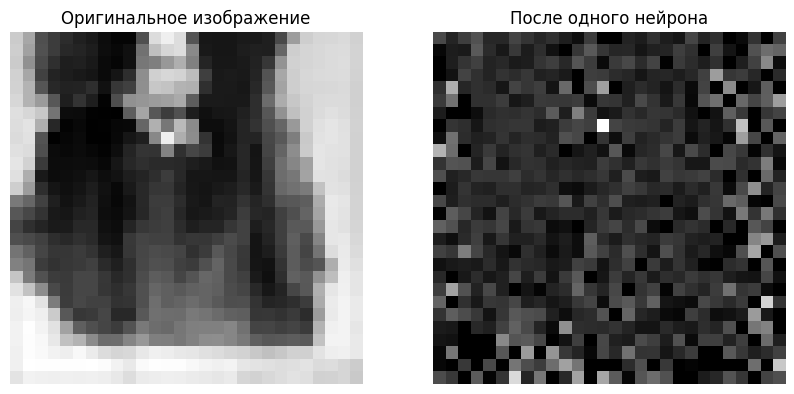

In [17]:
np.random.seed(42)
img = Image.open("data/image-3.png").convert("L")
img = img.resize((28, 28))
pixels = np.array(img) / 255.0
weights = np.random.randn(28 * 28)
bias = np.random.randn()


def relu(x):
    return np.maximum(0, x)


def pixelwise_neuron(pixels, weights, bias):
    flat = pixels.flatten()
    activated = relu(flat * weights + bias)
    return activated.reshape(pixels.shape)


processed = pixelwise_neuron(pixels, weights, bias)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(pixels, cmap="gray")
axs[0].set_title("Оригинальное изображение")
axs[0].axis("off")

axs[1].imshow(processed, cmap="gray")
axs[1].set_title("После одного нейрона")
axs[1].axis("off")

plt.show()

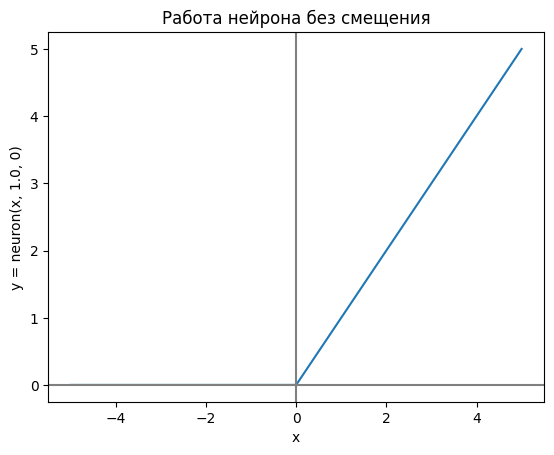

In [18]:
import matplotlib.pyplot as plt
import numpy as np


def relu(x):
    return np.maximum(0, x)


def neuron(x, weight, bias):
    return relu(weight * x + bias)


# Генерируем входные значения
x_vals = np.linspace(-5, 5, 200)
# Вычисляем выход нейрона без смещения (weight=1.0, bias=0)
y_vals = neuron(x_vals, weight=1.0, bias=0)

# Строим график
plt.plot(x_vals, y_vals)
plt.title("Работа нейрона без смещения")
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plt.xlabel("x")
plt.ylabel("y = neuron(x, 1.0, 0)")
plt.show()

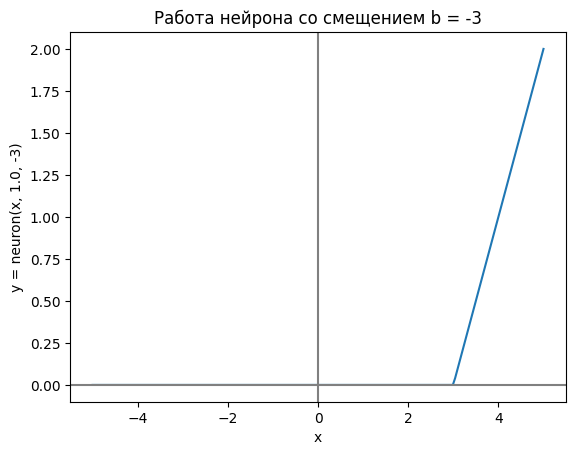

In [19]:
# Генерируем входные значения
x_vals = np.linspace(-5, 5, 200)
# Вычисляем выход нейрона со смещением (weight=1.0, bias)
y_vals = neuron(x_vals, weight=1.0, bias=-3)

# Строим график
plt.plot(x_vals, y_vals)
plt.title("Работа нейрона со смещением b = -3")
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plt.xlabel("x")
plt.ylabel("y = neuron(x, 1.0, -3)")
plt.show()

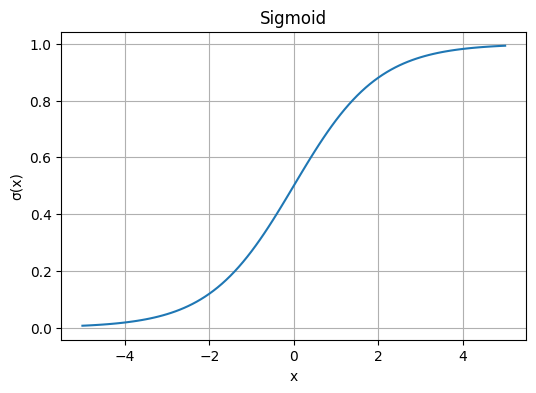

In [20]:
import math


def sigmoid(x: float) -> float:
    return 1 / (1 + math.exp(-x))


x_vals = [i * 0.1 for i in range(-50, 51)]  # Генерируем значения от -5 до 5 с шагом 0.1
y_vals = [sigmoid(x) for x in x_vals]  # Применяем функцию sigmoid к каждому значению

plt.figure(figsize=(6, 4))
plt.plot(x_vals, y_vals)
plt.title("Sigmoid")
plt.xlabel("x")
plt.ylabel("σ(x)")
plt.grid(True)
plt.show()

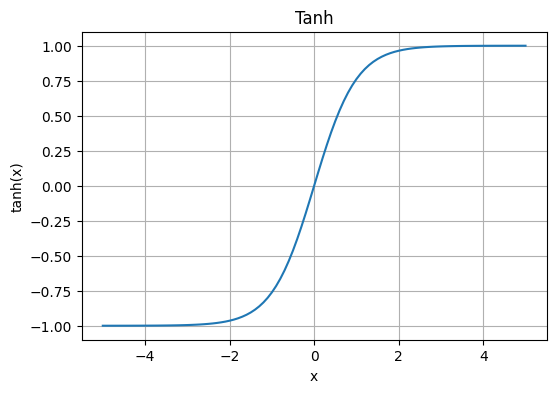

In [21]:
def tanh(x: float) -> float:
    return math.tanh(x)


x_vals = [i * 0.1 for i in range(-50, 51)]
y_vals = [tanh(x) for x in x_vals]
plt.figure(figsize=(6, 4))
plt.plot(x_vals, y_vals)
plt.title("Tanh")
plt.xlabel("x")
plt.ylabel("tanh(x)")
plt.grid(True)
plt.show()

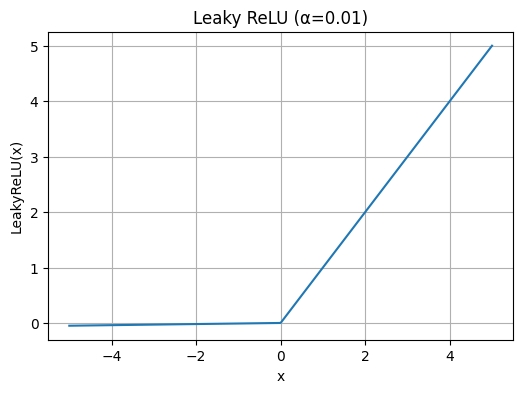

In [22]:
def leaky_relu(x, alpha=0.01):
    return np.where(x >= 0, x, alpha * x)


x_vals = np.linspace(-5, 5, 400)
y_vals = leaky_relu(x_vals)
plt.figure(figsize=(6, 4))
plt.plot(x_vals, y_vals)
plt.title("Leaky ReLU (α=0.01)")
plt.xlabel("x")
plt.ylabel("LeakyReLU(x)")
plt.grid(True)
plt.show()

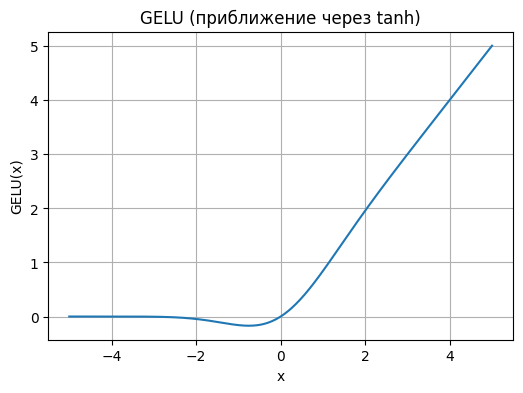

In [23]:
def gelu(x: np.ndarray) -> np.ndarray:
    # Приближение через tanh
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))


# Диапазон для визуализации
x_vals = np.linspace(-5, 5, 400)
y_vals = gelu(x_vals)

plt.figure(figsize=(6, 4))
plt.plot(x_vals, y_vals)
plt.title("GELU (приближение через tanh)")
plt.xlabel("x")
plt.ylabel("GELU(x)")
plt.grid(True)
plt.show()

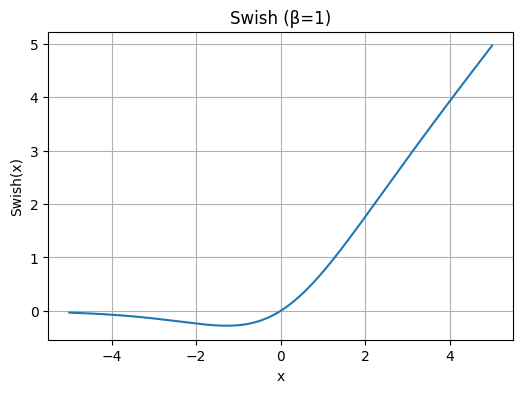

In [24]:
def sigmoid(x: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-x))


def swish(x: np.ndarray, beta: float = 1.0) -> np.ndarray:
    return x * sigmoid(beta * x)


# Диапазон для визуализации
x_vals = np.linspace(-5, 5, 400)
y_vals = swish(x_vals)

plt.figure(figsize=(6, 4))
plt.plot(x_vals, y_vals)
plt.title("Swish (β=1)")
plt.xlabel("x")
plt.ylabel("Swish(x)")
plt.grid(True)
plt.show()

In [ ]:
class MLP:
    def __init__(self, layer_sizes, activation="sigmoid"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W = []  # список матриц весов
        self.b = []  # список векторов смещений
        # Ваша задача заполнить self.W и self.b случайными параметрами
        for i in range(len(layer_sizes) - 1):
            in_dim = layer_sizes[i]
            out_dim = layer_sizes[i + 1]
            weight_matrix = np.random.randn(in_dim, out_dim) * 0.1
            bias_vector = np.zeros((1, out_dim))
            self.W.append(weight_matrix)
            self.b.append(bias_vector)

    def _sigmoid(self, Z):
        return 1 / (1 + np.exp(-Z))

    def _relu(self, Z):
        return np.maximum(0, Z)

    def forward(self, X):
        A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            # Вставьте ваш код здесь
            Z = np.dot(A, W) + b
            if self.activation == "sigmoid":
                A = self._sigmoid(Z)
            elif self.activation == "relu":
                A = self._relu(Z)
        return A

In [30]:
class MLP:
    def __init__(self, layer_sizes, activation="sigmoid"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W = []  # список матриц весов
        self.b = []  # список векторов смещений
        # Ваша задача заполнить self.W и self.b случайными параметрами
        for i in range(len(layer_sizes) - 1):
            in_dim = layer_sizes[i]
            out_dim = layer_sizes[i + 1]
            weight_matrix = np.random.randn(in_dim, out_dim) * 0.1
            bias_vector = np.zeros((1, out_dim))
            self.W.append(weight_matrix)
            self.b.append(bias_vector)

    def _sigmoid(self, Z):
        return 1 / (1 + np.exp(-Z))

    # Допишите метод forward
    def forward(self, X):
        A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A.dot(W) + b
            if i < len(self.W) - 1:
                A = self._sigmoid(Z)
            else:
                A = Z  # линейный выход для последнего слоя
        return A


# Запускаем модель
np.random.seed(42)
# Инициализируем модель с 4 слоями: 10 входов, 32 нейрона, 16 нейронов и 5 выходов
model = MLP([10, 32, 16, 5], activation="sigmoid")
# Создаём случайный входной массив размером 100 примеров по 10 признаков
X_rand = np.random.randn(100, 10)
# Запускаем прямой проход
out = model.forward(X_rand)
print("Output shape:", out.shape)
# ожидаем (100, 5)

Output shape: (100, 5)


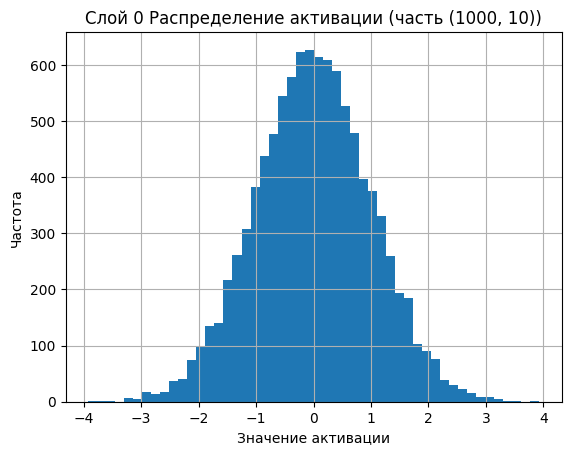

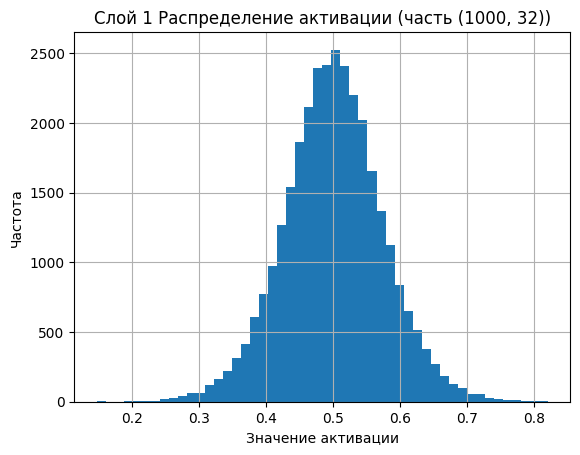

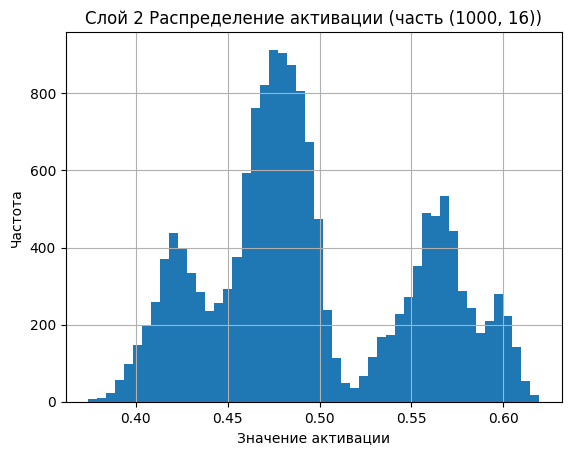

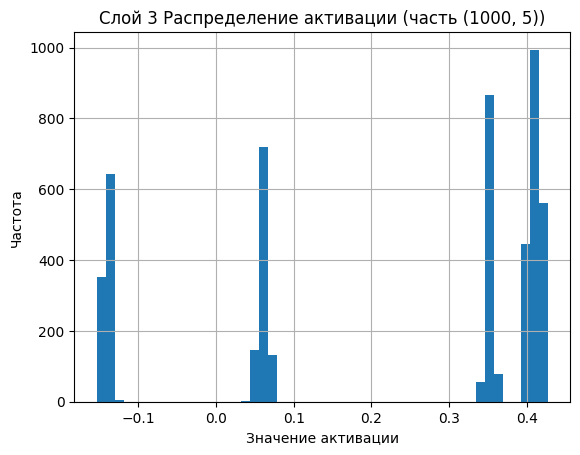

In [31]:
import matplotlib.pyplot as plt


class MLP:
    def __init__(self, layer_sizes, activation="sigmoid"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W = []
        self.b = []
        for i in range(len(layer_sizes) - 1):
            in_dim = layer_sizes[i]
            out_dim = layer_sizes[i + 1]
            weight_matrix = np.random.randn(in_dim, out_dim) * 0.1
            bias_vector = np.zeros((1, out_dim))
            self.W.append(weight_matrix)
            self.b.append(bias_vector)

    def _sigmoid(self, Z):
        return 1 / (1 + np.exp(-Z))

    def forward_with_activations(self, X):
        activations = [X]
        A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A.dot(W) + b
            if i < len(self.W) - 1:
                A = self._sigmoid(Z)
            else:
                A = Z
            activations.append(A)
        return activations


# Инициализируем модель с 4 слоями: 10 входов, 32 нейрон, 16 нейронов и 5 выходов
np.random.seed(42)
model = MLP([10, 32, 16, 5], activation="sigmoid")
X_rand = np.random.randn(1000, 10)

# Соберем активации
acts = model.forward_with_activations(X_rand)

# Отобразим активации каждого слоя
for idx, A in enumerate(acts):
    plt.figure()
    plt.hist(A.flatten(), bins=50)
    plt.title(f"Слой {idx} Распределение активации (часть {A.shape})")
    plt.xlabel("Значение активации")
    plt.ylabel("Частота")
    plt.grid(True)
    plt.show()

In [32]:
import numpy as np


class MLP:
    def __init__(self, layer_sizes, activation="sigmoid"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        # сюда будем складывать Z и A
        self.Z_list, self.A_list = [], []

        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i + 1]
            self.W.append(np.random.randn(in_dim, out_dim) * 0.1)
            self.b.append(np.zeros((1, out_dim)))

    def _sigmoid(self, Z):
        return 1 / (1 + np.exp(-Z))

    def _relu(self, Z):
        return np.maximum(0, Z)

    def forward(self, X):
        # очищаем списки перед новым вызовом
        self.Z_list, self.A_list = [], []
        A = X
        # сохраните инициализацию входного слоя в A_list
        self.A_list.append(A)

        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A.dot(W) + b
            self.Z_list.append(Z)

            if i < len(self.W) - 1:
                if self.activation == "sigmoid":
                    A = self._sigmoid(Z)
                elif self.activation == "relu":
                    A = self._relu(Z)
                else:
                    raise ValueError(f"Unknown activation {self.activation}")
            else:
                A = Z

            self.A_list.append(A)

        return A

In [ ]:
class MLP:
    def __init__(self, layer_sizes, activation="sigmoid"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        # сюда будем складывать Z и A
        self.Z_list, self.A_list = [], []

        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i + 1]
            self.W.append(np.random.randn(in_dim, out_dim) * 0.1)
            self.b.append(np.zeros((1, out_dim)))

    def _sigmoid(self, Z):
        return 1 / (1 + np.exp(-Z))

    def _relu(self, Z):
        return np.maximum(0, Z)

    def _tanh(self, Z):
        return np.tanh(Z)

    def forward(self, X):
        # очищаем списки перед новым вызовом
        self.Z_list, self.A_list = [], []
        A = X
        # сохраните активацию входного слоя в A_list
        self.A_list.append(A)

        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A.dot(W) + b
            self.Z_list.append(Z)

            if i < len(self.W) - 1:
                if self.activation == "sigmoid":
                    A = self._sigmoid(Z)
                elif self.activation == "relu":
                    A = self._relu(Z)
                elif self.activation == "tanh":
                    A = self._tanh(Z)  # Ваш код здесь
                else:
                    raise ValueError(f"Unknown activation {self.activation}")
            else:
                A = Z

            self.A_list.append(A)

        return A


x = np.array([[1.0, 2.0, -1.0]])
for act in ["relu", "sigmoid", "tanh"]:
    np.random.seed(0)
    model = MLP([3, 2, 1], activation=act)
    y_pred = model.forward(x)
    print(
        f"{act}: y_pred={y_pred.ravel()[0]:.4f}, "
        f"len(Z_list)={len(model.Z_list)}, len(A_list)={len(model.A_list)}"
    )

    # Отобразим значения Z и A
    for i, (Z, A) in enumerate(zip(model.Z_list, model.A_list)):
        print(f"Layer {i}: Z={Z.ravel()}, A={A.ravel()}")
    print()

In [ ]:
def mse(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)

In [34]:
import numpy as np

w = 1.0
x = 2.0
y_true = 10.0


def loss(w):
    # Предсказание
    y_pred = w * x
    return mse(y_pred, y_true)
    # Используйте функцию потерь MSE
    # Ваш код здесь


print("Исходная потеря:", loss(w))
for h in [0.01, -0.01]:
    l_new = loss(w + h)
    print(f"w изменился на {h:+.2f}, новая потеря: {l_new}")

NameError: name 'mse' is not defined